<a href="https://colab.research.google.com/github/johnmichaels4867-create/ACCTG5150/blob/main/Lab_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('/content/financial_data_lab8.csv')

def scatter_r2(df, x, y, title, xlabel, ylabel, filename, scale=1e3, xlim=None, ylim=None):
    d = df[[x, y]].dropna(how='any') / scale
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.regplot(x=x, y=y, data=d, scatter_kws={'alpha': .15}, line_kws={'color': 'black'}, ax=ax)
    r = stats.linregress(d[x], d[y]).rvalue
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    ax.text(0.05, 0.95, f'$R^2$ = {r**2:.3f}', transform=ax.transAxes, fontsize=12, va='top')
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()
    print(f'R² = {r**2:.3f}  (n = {len(d)})')

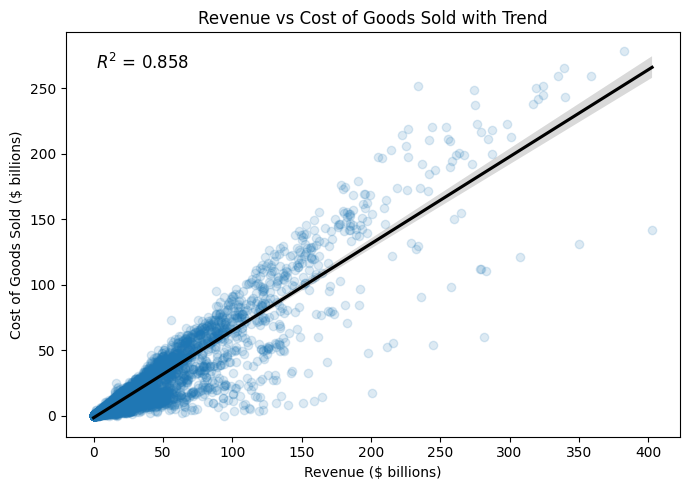

R² = 0.858  (n = 6761)


In [5]:
#2
scatter_r2(df, 'revt', 'cogs',
           'Revenue vs Cost of Goods Sold with Trend',
           'Revenue ($ billions)', 'Cost of Goods Sold ($ billions)',
           'revt_cogs.png')

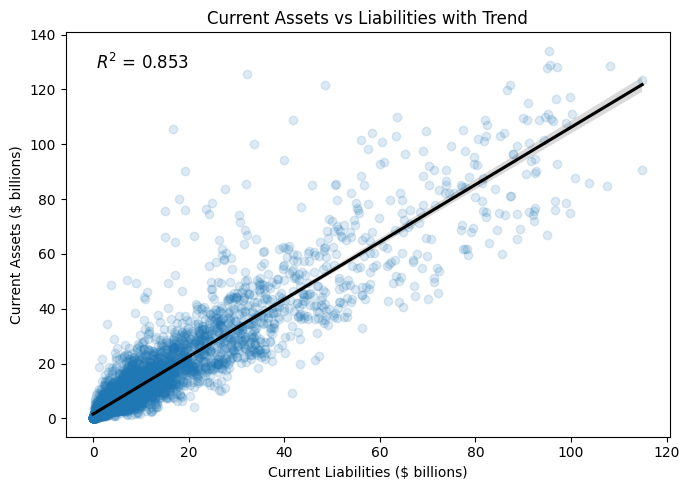

R² = 0.853  (n = 5603)


In [9]:
#3
scatter_r2(df, 'lct', 'act',
           'Current Assets vs Liabilities with Trend',
           'Current Liabilities ($ billions)', 'Current Assets ($ billions)',
           'act_lct.png')

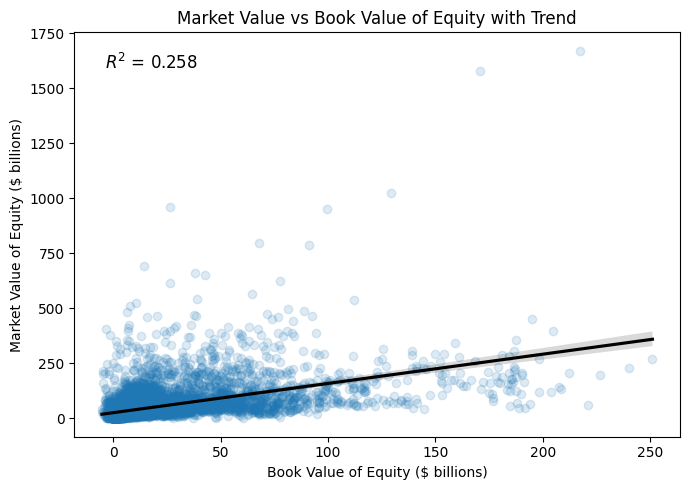

R² = 0.258  (n = 6650)


In [10]:
#4
scatter_r2(df, 'bve', 'mve',
           'Market Value vs Book Value of Equity with Trend',
           'Book Value of Equity ($ billions)', 'Market Value of Equity ($ billions)',
           'bve_mve.png')

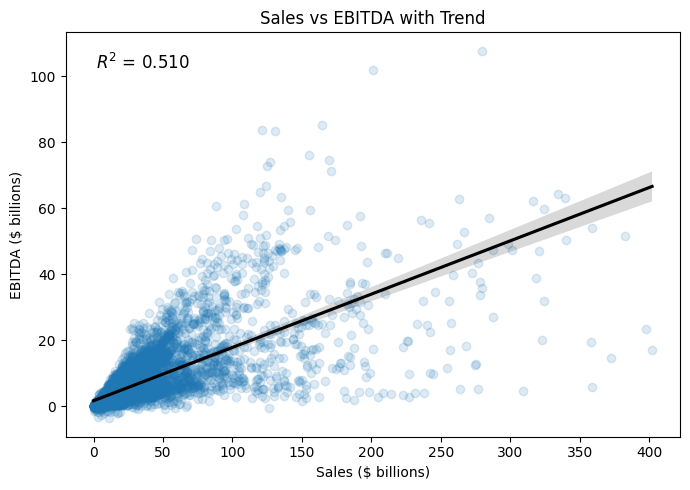

R² = 0.510  (n = 6360)


In [8]:
#5
scatter_r2(df, 'sale', 'ebitda',
           'Sales vs EBITDA with Trend',
           'Sales ($ billions)', 'EBITDA ($ billions)',
           'sale_ebitda.png')

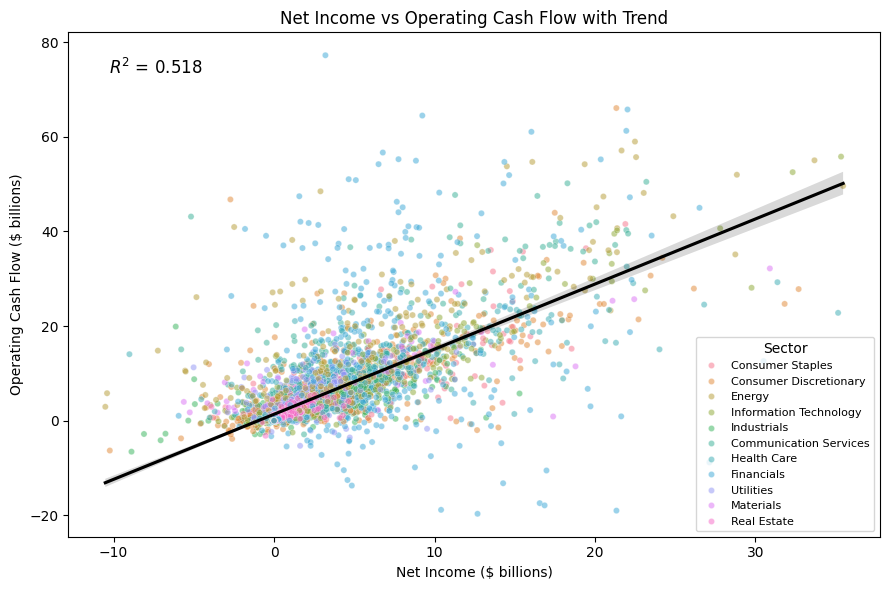

In [11]:
d = df[['ni', 'oancf', 'gics_sector_name']].dropna()
d[['ni', 'oancf']] = d[['ni', 'oancf']] / 1e3   # millions -> billions

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x='ni', y='oancf', hue='gics_sector_name', data=d, alpha=.5, s=20, ax=ax)
sns.regplot(x='ni', y='oancf', data=d, scatter=False, line_kws={'color': 'black'}, ax=ax)

r = stats.linregress(d['ni'], d['oancf']).rvalue
ax.set_title('Net Income vs Operating Cash Flow with Trend')
ax.set_xlabel('Net Income ($ billions)')
ax.set_ylabel('Operating Cash Flow ($ billions)')
ax.text(0.05, 0.95, f'$R^2$ = {r**2:.3f}', transform=ax.transAxes, fontsize=12, va='top')
ax.legend(title='Sector', fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig('ni_oancf.png', dpi=200)
plt.show()